## Knee Osteoarthritis Dataset with Severity Grading from Dataset Exploration

This Notebook explores a dataset of knee X-rays used to detect osteoarthritis levels (Grade 0 to 4). To optimize CVRIE's learning, we will transform this multi-class problem into a binary classification:

- Healthy (Class 0): Grade 0 images.
-  Sick (Class 1): Combination of Grades 1, 2, 3, and 4.

Dataset structure
- train/
- val/
- test/

Classes or Labels
- healthy
- sick

Goals:
-  Analyze the distribution: Count images in each of the 5 original grades.
-  Data Balancing: Implement a proportional reduction of "Sick" cases to match the number of "Healthy" cases. This prevents the model from being biased toward the majority class.
- Visualization: Display samples of the different grades to understand the progression of the disease.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import random

## Dataset Dir and Labels

In [2]:
train_dir = "../Dataset_Knee_Osteoarthritis_Balanced/train"
val_dir = "../Dataset_Knee_Osteoarthritis_Balanced/val"
test_dir = "../Dataset_Knee_Osteoarthritis_Balanced/test"

print("Labels found in Train:", os.listdir(train_dir))


Labels found in Train: ['sick', 'healthy']


## Nbr of images per classes for each dir

In [3]:
def count_images_in_dir(base_dir):
    total = 0
    for label in os.listdir(base_dir):
        path = os.path.join(base_dir, label)
        total += len(os.listdir(path))
    return total

print("Total Train images:", count_images_in_dir(train_dir))
print("Total Validation images:", count_images_in_dir(val_dir))
print("Total Test images:", count_images_in_dir(test_dir))


Total Train images: 4570
Total Validation images: 653
Total Test images: 1276


### Dataset size analysis

The count_images function reveal that the validations folder has 653 images, which is significantly smaller than the train set and test set.
This may limit the reliability of validation metrics during model training.

 ## Class Balance Verification

In [4]:
def count_per_class(base_dir):
    counts = {}
    for label in os.listdir(base_dir):
        path = os.path.join(base_dir, label)
        counts[label] = len(os.listdir(path))
    return counts

train_balance = count_per_class(train_dir)
test_balance = count_per_class(test_dir)

print("Train balance:", train_balance)
print("Test balance:", test_balance)


Train balance: {'sick': 2284, 'healthy': 2286}
Test balance: {'sick': 637, 'healthy': 639}


### Visualization of the imbalanced

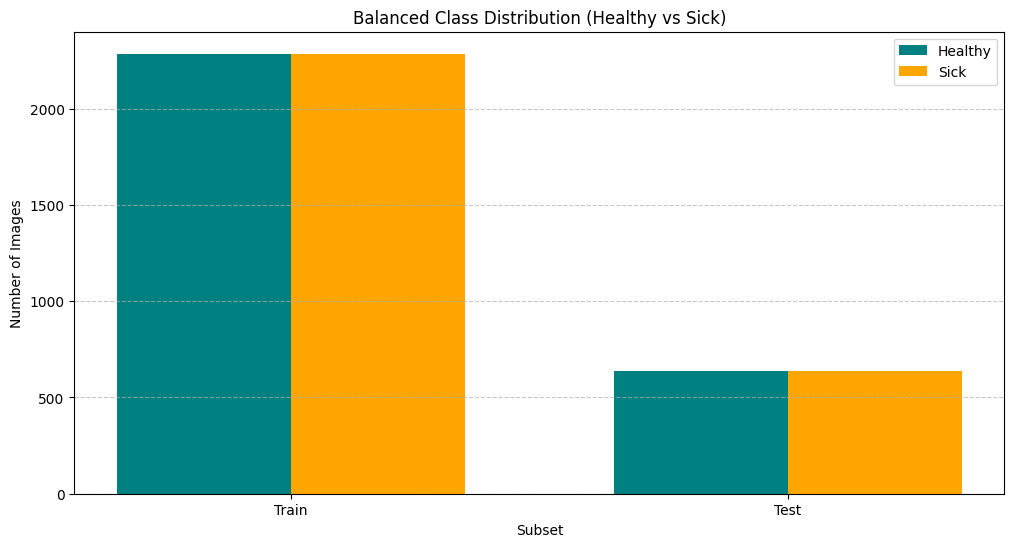

In [5]:
def plot_distribution():
    labels = ["Train", "Test"]
    healthy_counts = [train_balance["healthy"], test_balance["healthy"]]
    sick_counts = [train_balance["sick"], test_balance["sick"]]

    x = np.arange(len(labels))
    width = 0.35
    plt.figure(figsize=(12, 6))

    plt.bar(x - width/2, healthy_counts, width, label="Healthy", color="teal")
    plt.bar(x + width/2, sick_counts, width, label="Sick", color="orange")

    plt.xlabel("Subset")
    plt.ylabel("Number of Images")
    plt.title("Balanced Class Distribution (Healthy vs Sick)")
    plt.xticks(x, labels)
    plt.legend()
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()

plot_distribution()


### Class Distribution Analysis

The distribution is now perfectly balanced (1:1 ratio). By reducing the majority class (Sick) using a proportional undersampling strategy, we have eliminated the risk of model bias. The model will now learn to identify both classes with equal importance.

## Visualizing Samples

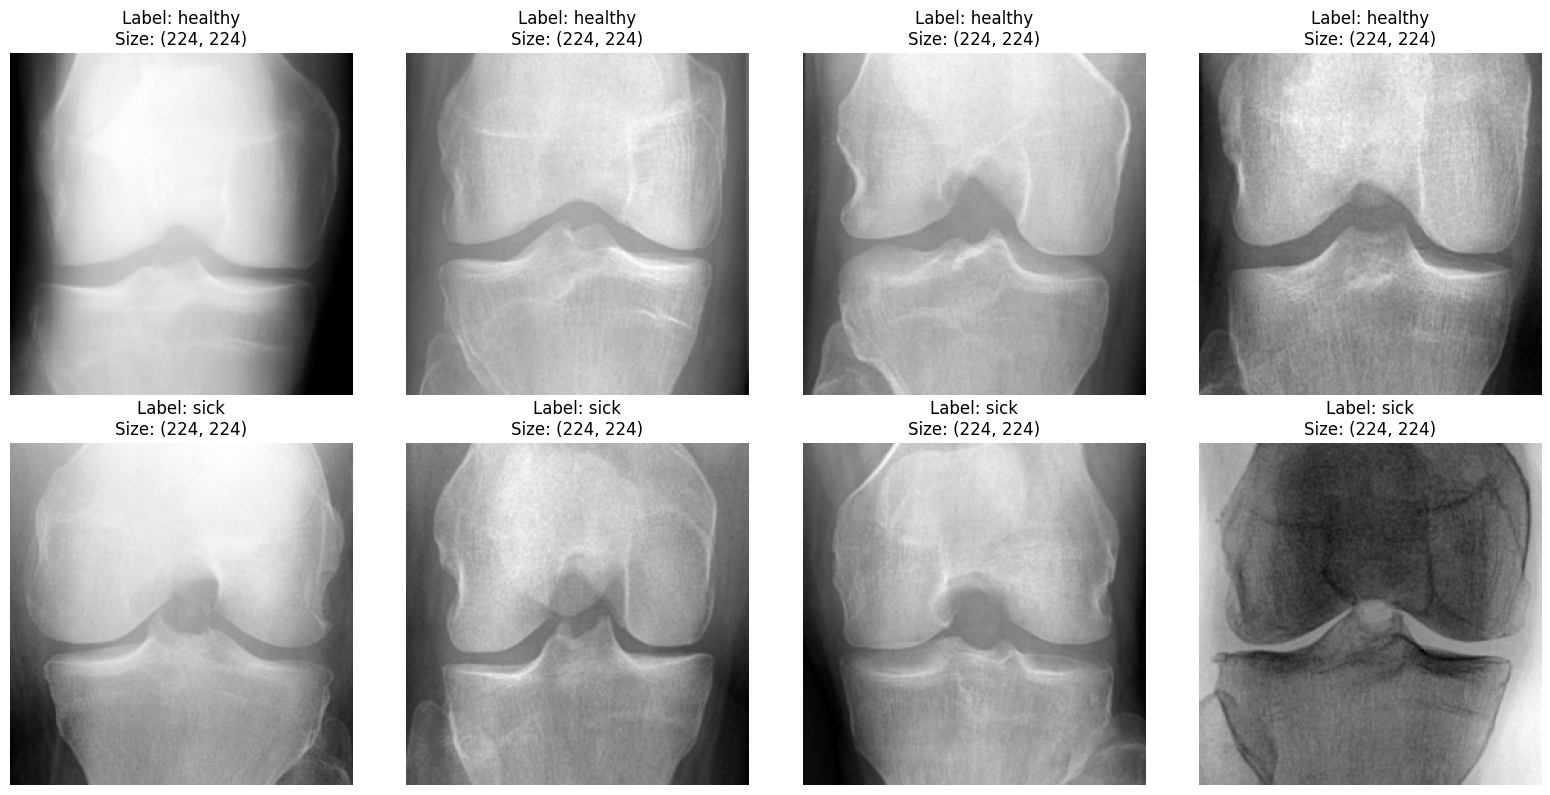

In [6]:
def display_random_samples(base_dir, labels=['healthy', 'sick'], n=4):
    plt.figure(figsize=(16, 8))
    for i, category in enumerate(labels):
        folder_path = os.path.join(base_dir, category)
        img_names = random.sample(os.listdir(folder_path), n)
        
        for j, img_name in enumerate(img_names):
            plt.subplot(len(labels), n, i * n + j + 1)
            img_path = os.path.join(folder_path, img_name)
            img = Image.open(img_path)
            
            plt.imshow(img, cmap='gray')
            plt.title(f"Label: {category}\nSize: {img.size}")
            plt.axis('off')
            
    plt.tight_layout()
    plt.show()

display_random_samples(train_dir)
